# Análise dos Dados: TTPLA Dataset
***
* Repositório com o dataset original: [TTPLA Dataset](https://github.com/R3ab/ttpla_dataset).
* Publicação do artigo científico: [TTPLA: An Aerial-Image Dataset for Detection and Segmentation of Transmission Towers and Power Lines](https://arxiv.org/pdf/2010.10032.pdf).

### Importação dos Pacotes Utilitários
***

In [8]:
import matplotlib.pyplot as plt
import json, os
import utils

### Análise dos Dados
***

Tipos de classes de objetos distintos explorados no conjunto de imagens proposto:

* ```tower_lattice```: Torres de aço cuja estrutura é composta por treliças.
* ```tower_tucohy```: Torres feitas de aço tubular, concreto armado e postes híbridos de aço/concreto.
* ```tower_wooden```: Torres voltadas para instalação em áreas urbanas e feitas de madeira.
* ```cable```: Cabos de linha de transmissão.
* ```void```: Objetos parecidas com alguma das instâncias acima, mas que sua rotulagem é incerta.

In [9]:
# carregando os arquivos .json em uma lista
labels_folder = '../datasets-descompactados/TTPLA-dataset/'
jsons_files = utils.list_json_files(labels_folder)
jsons_files = sorted(jsons_files, key = utils.extract_number)

In [10]:
# contando a quantidade de objetos instanciados por classe em cada uma das imagens
count_category_counts = list()

for json_file in jsons_files:
    category_counts = utils.count_categories('../datasets-descompactados/TTPLA-dataset/' + json_file)
    count_category_counts.append(category_counts)

In [11]:
# contando a quantidade de objetos instanciados por classe em todo o conjunto de imagens
tower_tucohy, tower_lattice, tower_wooden, cable, void = 0, 0, 0, 0, 0 

for category in count_category_counts:
    keys = category.keys()
    for key in keys:
        count = category[key]
        if key == 'tower_tucohy': tower_tucohy += count
        elif key == 'tower_lattice': tower_lattice += count
        elif key == 'tower_wooden': tower_wooden += count
        elif key == 'cable': cable  += count
        elif key == 'void': void += count

total_instances = {'Tower Tucohy': tower_tucohy, 'Tower Lattice': tower_lattice,
                   'Tower Wooden': tower_wooden, 'Cable': cable, 'Void': void}

print(total_instances)

{'Tower Tucohy': 231, 'Tower Lattice': 404, 'Tower Wooden': 333, 'Cable': 10075, 'Void': 396}


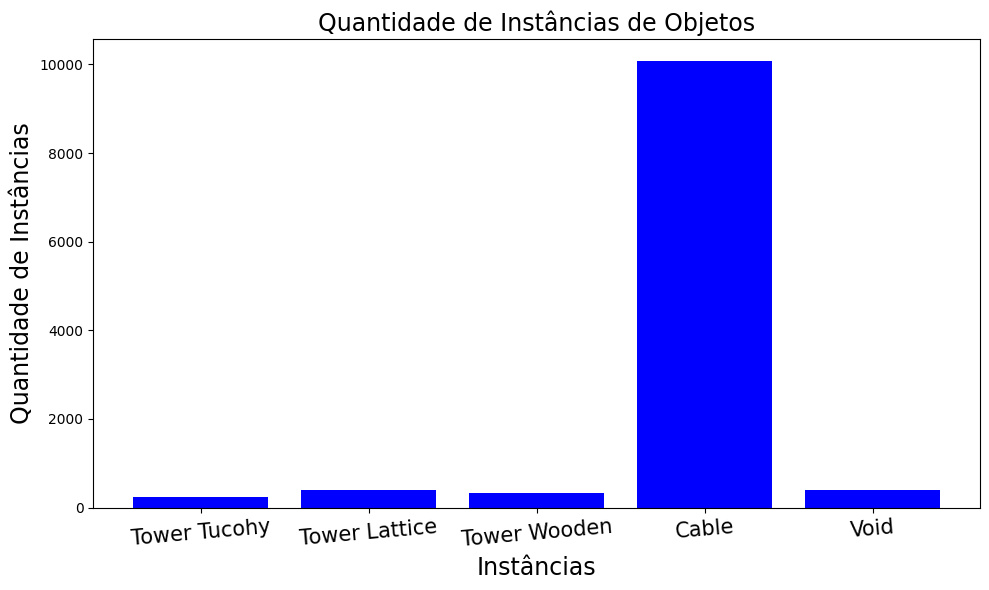

In [12]:
# extraindo as chaves e os valores do dicionário
classes = list(total_instances.keys())
quantities = list(total_instances.values())

# configurações para a plotagem do gráfico de barras
plt.figure(figsize = (10, 6))  

plt.bar(classes, quantities, color = 'blue')  

plt.xlabel('Instâncias', size = 17)
plt.ylabel('Quantidade de Instâncias', size = 17)
plt.title('Quantidade de Instâncias de Objetos', size = 17)
plt.xticks(rotation = 5, size = 15)  

plt.tight_layout()  
plt.show()  

In [13]:
power_towers, urban_towers, no_power_towers = 0, 0, 0

for category in count_category_counts:
    keys = category.keys()
    for key in keys:
        count = category[key]
        if (key == 'tower_tucohy') | (key == 'tower_lattice'): 
            power_towers += 1
            break
        elif key == 'tower_wooden':
            urban_towers += 1
            break
        else: 
            no_power_towers += 1
            break

power_towers_total_images = {'Imagens com Torres': power_towers, 
                             'Postes de Madeira': urban_towers,
                             'Imagens sem Torres': no_power_towers}

print(power_towers_total_images)

{'Imagens com Torres': 279, 'Postes de Madeira': 113, 'Imagens sem Torres': 850}


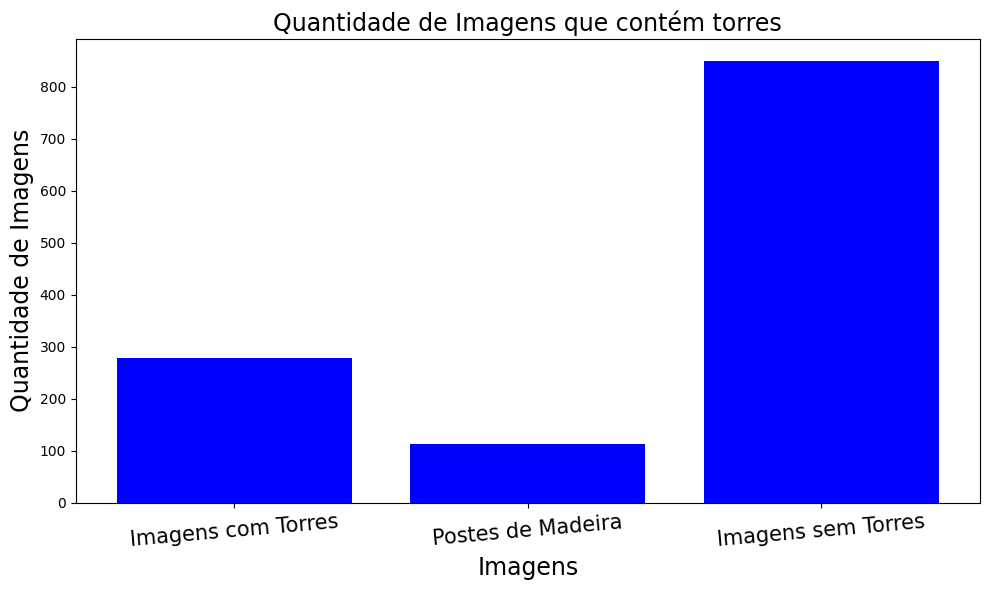

In [14]:
# extraindo as chaves e os valores do dicionário
classes = list(power_towers_total_images.keys())
quantities = list(power_towers_total_images.values())

# configurações para a plotagem do gráfico de barras
plt.figure(figsize = (10, 6))  

plt.bar(classes, quantities, color='blue')  

plt.xlabel('Imagens', size = 17)
plt.ylabel('Quantidade de Imagens', size = 17)
plt.title('Quantidade de Imagens que contém torres', size = 17)
plt.xticks(rotation = 5, size = 15)  

plt.tight_layout()  
plt.show()  